# Data Mining Exercise 4 — SVM, Random Forest & XGBoost on Iris

Iris veri seti üzerinde SVM (linear, RBF gamma=0.01/0.1/1, Polynomial p=2/3), Random Forest ve XGBoost yöntemleri k-fold (k=3 ve 5) ile değerlendirilir. Her yapılandırma için StandardScaler + model pipeline'ı kurulur ve çapraz doğrulama ile ortalama accuracy ve macro F1 hesaplanır.

### Random State
Sabit `random_state` ile sonuçlar tekrarlanabilir hale getirilir.

In [7]:
RS = 42

## Imports
Gerekli kütüphaneler içe aktarılır.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

## Load Iris Dataset
scikit-learn'dan Iris veri seti yüklenir ve DataFrame'e dönüştürülür.

In [9]:
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['class'] = iris.target
X = df.drop(columns=['class'])
y = df['class']
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),class
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## Model Configurations
Değerlendirilecek tüm model yapılandırmaları tek bir listede toplanır. Her kayıt bir isim ve scikit-learn estimator'ı içerir.

In [10]:
configs = []
# SVM - linear
configs.append(('SVM linear', SVC(kernel='linear', random_state=RS)))
# SVM - RBF with different gamma
for g in [0.01, 0.1, 1]:
    configs.append((f'SVM RBF gamma={g}', SVC(kernel='rbf', gamma=g, random_state=RS)))
# SVM - Polynomial degree 2, 3
for d in [2, 3]:
    configs.append((f'SVM Poly p={d}', SVC(kernel='poly', degree=d, random_state=RS)))
# Random Forest
configs.append(('Random Forest', RandomForestClassifier(n_estimators=100, random_state=RS)))
# XGBoost
configs.append(('XGBoost', XGBClassifier(n_estimators=100, eval_metric='mlogloss', random_state=RS)))

len(configs)

8

## k-Fold Cross-Validation
Her model yapılandırması k=3 ve k=5 için KFold ile değerlendirilir. StandardScaler pipeline içinde yer alır (veri sızıntısını önler). Sonuçlar tablo olarak toplanır.

In [11]:
reports = []
for name, estimator in configs:
    for k in [3, 5]:
        kf = KFold(n_splits=k, shuffle=True, random_state=RS)
        pipe = Pipeline([('scaler', StandardScaler()), ('model', estimator)])
        acc = cross_val_score(pipe, X, y, cv=kf, scoring='accuracy')
        f1 = cross_val_score(pipe, X, y, cv=kf, scoring='f1_macro')
        reports.append({
            'model': name,
            'k_fold': k,
            'mean_accuracy': acc.mean(),
            'std_accuracy': acc.std(),
            'mean_f1_macro': f1.mean(),
        })

results_df = pd.DataFrame(reports).sort_values('mean_accuracy', ascending=False).reset_index(drop=True)
results_df

,model,k_fold,mean_accuracy,std_accuracy,mean_f1_macro
0,SVM linear,5,0.973333,0.013333,0.971271
1,SVM RBF gamma=0.1,5,0.966667,0.021082,0.964725
2,Random Forest,5,0.966667,0.021082,0.964910
3,SVM linear,3,0.966667,0.009428,0.965736
4,SVM RBF gamma=0.1,3,0.960000,0.016330,0.959456
5,Random Forest,3,0.960000,0.016330,0.959957
6,SVM RBF gamma=1,5,0.953333,0.026667,0.951078
7,SVM RBF gamma=1,3,0.946667,0.024944,0.945781
8,XGBoost,5,0.946667,0.033993,0.945263
9,XGBoost,3,0.940000,0.028284,0.940871


## Results Visualization
Model yapılandırmalarının ortalama accuracy değerleri çubuk grafik ile karşılaştırılır.

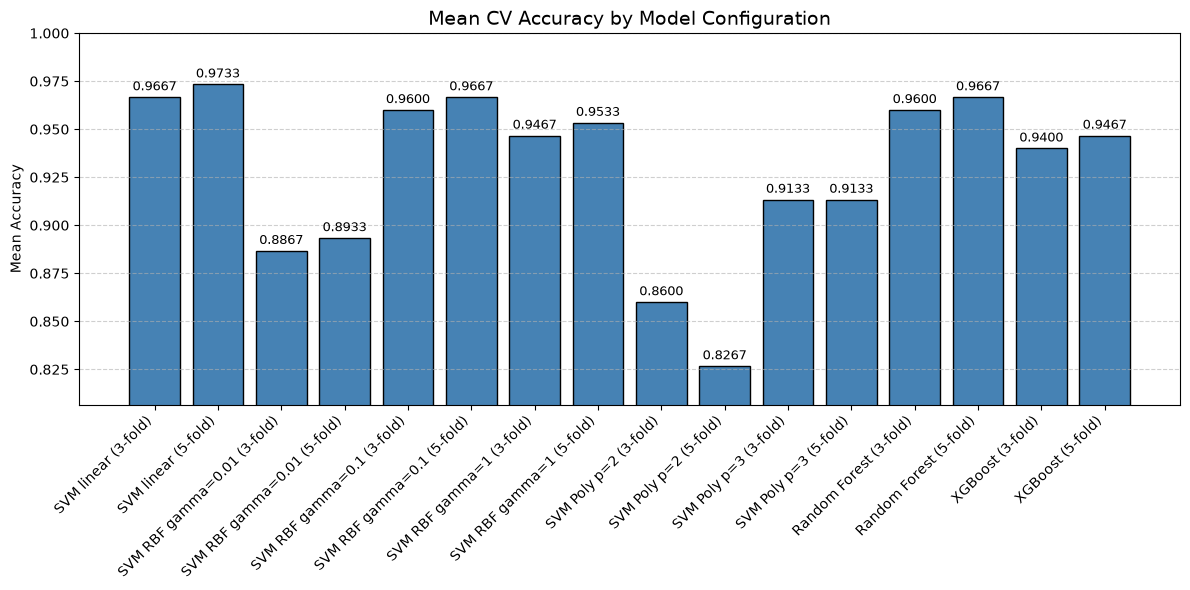

In [12]:
labels = [f"{r['model']} ({r['k_fold']}-fold)" for r in reports]
accs = [r['mean_accuracy'] for r in reports]

plt.figure(figsize=(12, 6))
bars = plt.bar(labels, accs, color='steelblue', edgecolor='black')
for bar in bars:
    v = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, v + 0.002, f"{v:.4f}", ha='center', va='bottom', fontsize=9)
plt.title('Mean CV Accuracy by Model Configuration', fontsize=14)
plt.ylabel('Mean Accuracy')
plt.xticks(rotation=45, ha='right')
plt.ylim(min(accs) - 0.02, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Conclusion
Tablo ve grafikten en yüksek ortalama accuracy değerine sahip yapılandırma seçilebilir. Iris veri seti büyük ölçüde doğrusal olarak ayrılabilir olduğundan SVM linear ve RBF (düşük gamma) genellikle yüksek performans verir; ağaç tabanlı yöntemler (Random Forest, XGBoost) de güçlü sonuçlar üretir. k=5 genellikle k=3'e göre daha düşük varyanslı tahmin sunar.

### References
- https://scikit-learn.org/stable/modules/svm.html
- https://scikit-learn.org/stable/modules/ensemble.html
- https://xgboost.readthedocs.io/

## Decision Boundaries (Petal Length & Petal Width)
Her model yapılandırması sadece petal length ve petal width özellikleri ile yeniden eğitilir ve karar sınırları çizilir. Bu, modellerin 2D uzayda sınıfları nasıl ayırdığını görselleştirir.

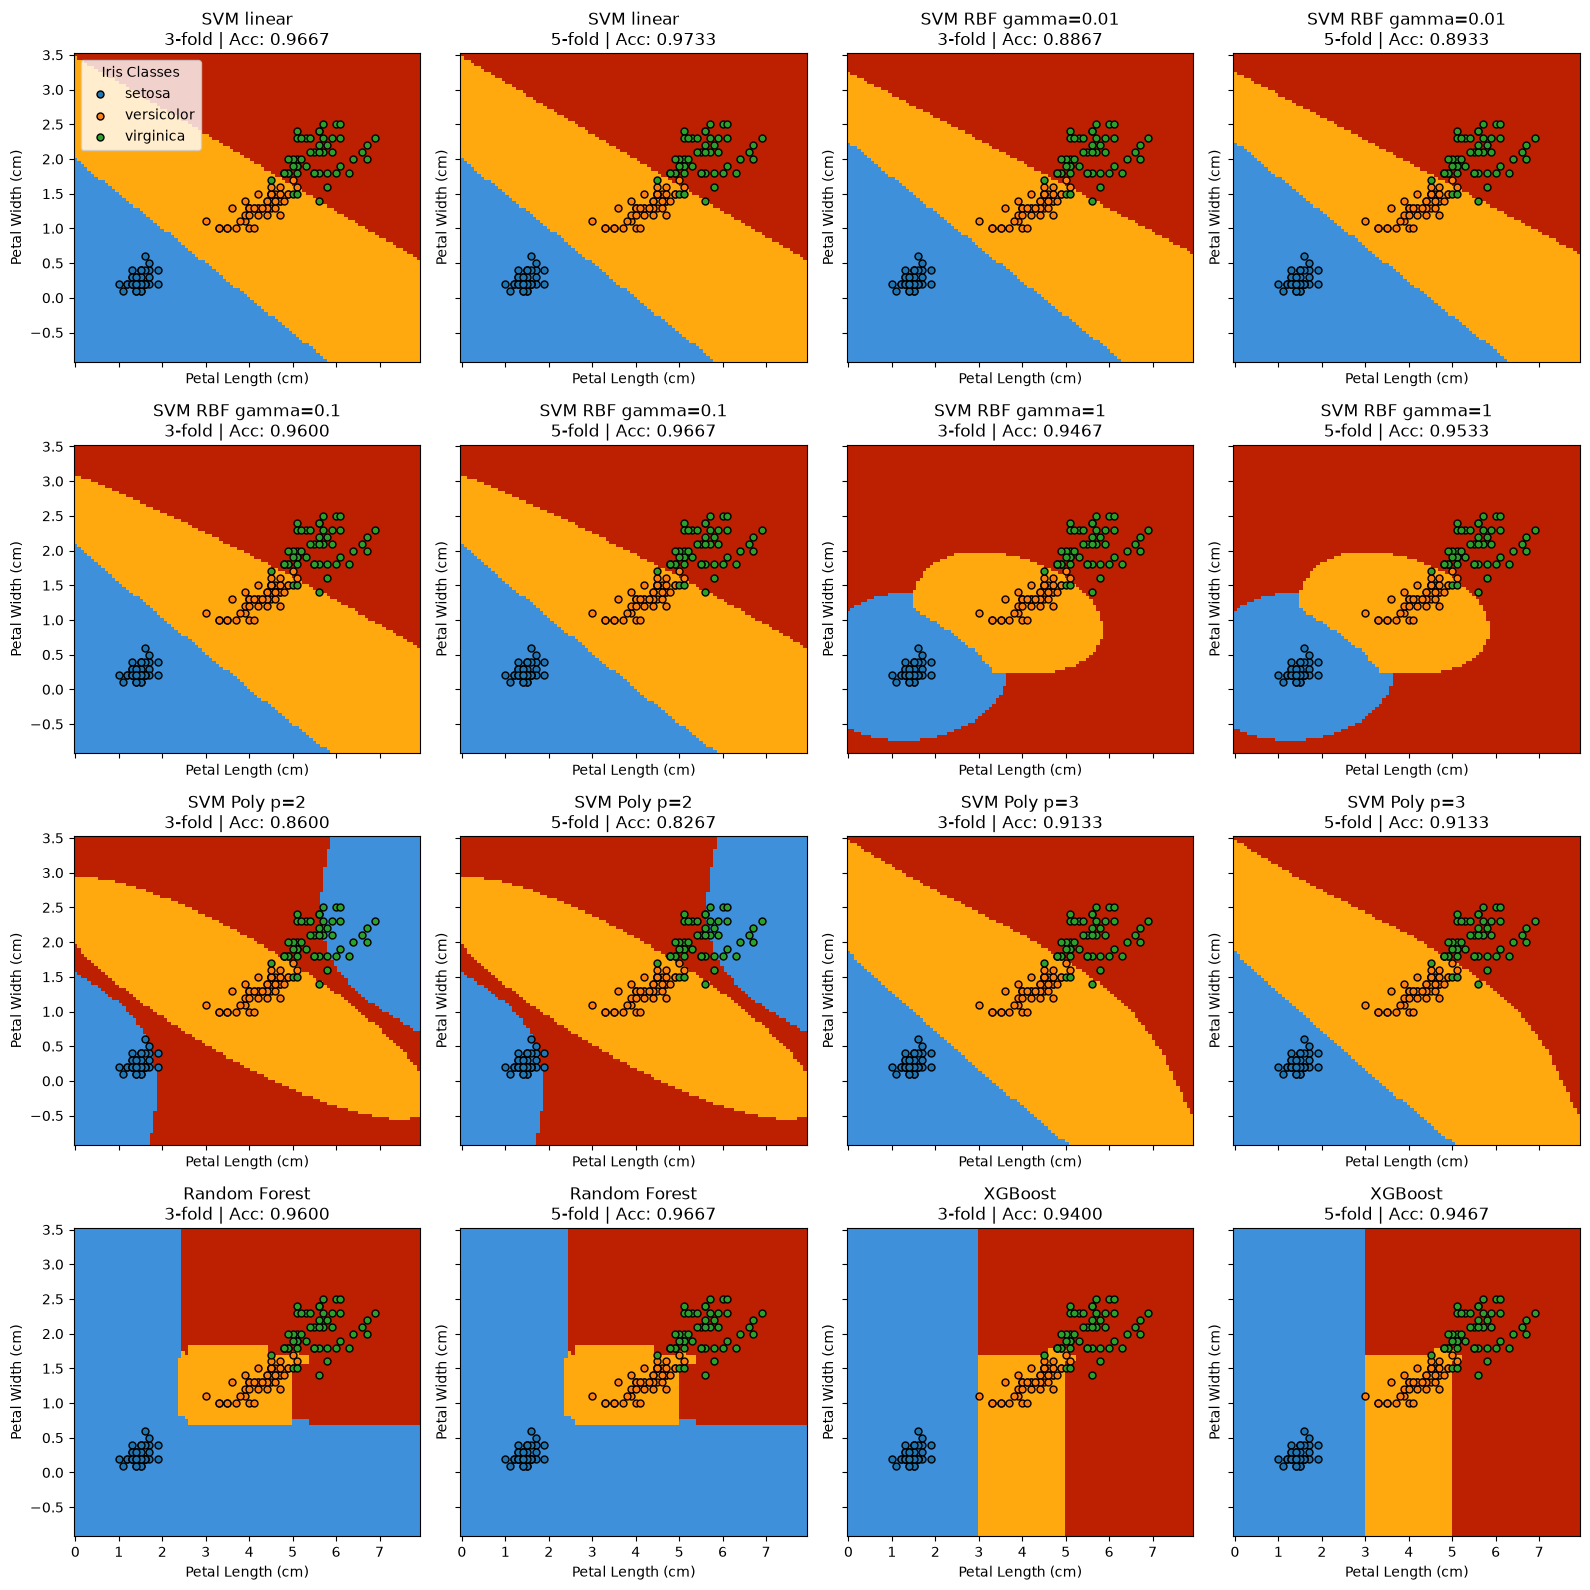

In [13]:
import math
from sklearn.base import clone
from sklearn.inspection import DecisionBoundaryDisplay

X_2d = X[['petal length (cm)', 'petal width (cm)']]

n = len(reports)
cols = 4
rows = math.ceil(n / cols)
fig, axes = plt.subplots(rows, cols, figsize=(16, 4*rows), sharex=True, sharey=True)
axes = np.atleast_1d(axes).flatten()

for idx, r in enumerate(reports):
    ax = axes[idx]
    # find original estimator factory by name
    est = None
    for name, e in configs:
        if name == r['model']:
            est = e
            break
    model_2d = clone(est)
    pipe_2d = Pipeline([('scaler', StandardScaler()), ('model', model_2d)])
    pipe_2d.fit(X_2d, y)
    DecisionBoundaryDisplay.from_estimator(
        pipe_2d, X_2d, response_method='predict',
        plot_method='pcolormesh', shading='auto', ax=ax,
        xlabel='Petal Length (cm)', ylabel='Petal Width (cm)'
    )
    for cls in np.unique(y):
        mask = (y == cls)
        ax.scatter(X_2d.loc[mask, 'petal length (cm)'],
                   X_2d.loc[mask, 'petal width (cm)'],
                   edgecolors='k', s=25, label=iris.target_names[cls] if idx == 0 else '')
    ax.set_title(f"{r['model']}\n{r['k_fold']}-fold | Acc: {r['mean_accuracy']:.4f}")

for idx in range(n, len(axes)):
    fig.delaxes(axes[idx])
if n > 0:
    axes[0].legend(title='Iris Classes', loc='upper left')
plt.tight_layout()
plt.show()